In [1]:
%pip install numpy matplotlib nbconvert scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05


Note: you may need to restart the kernel to use updated packages.


# GPS Positioning and Relativity

A GPS receiver calculates its position from time. Each satellite sends its own clock
time. The receiver measures the time the signal takes to arrive. The receiver
multiplies this time by the speed of light. The result is a range.

Light travels about 30 cm in one nanosecond. So the clocks must agree to within
nanoseconds. Relativity is not a theoretical detail here. It is a practical engineering
requirement. If the clocks are wrong, the calculated position is wrong.


## Why We Need Relativity

A satellite clock and a ground clock do not tick at the same rate. Two relativistic
effects cause this difference. The two effects act in opposite directions.

**Effect 1: Gravitational time dilation (general relativity).**
A clock deep in a gravity well runs slower. A clock high in the well runs faster. The
satellite orbits about 20,200 km above Earth. At this altitude, Earth's gravity is
weaker than at the ground. So the satellite clock runs faster than a ground clock:

$$\Big(\tfrac{\Delta f}{f}\Big)_{\mathrm{GR}}=\frac{\Phi_\mathrm{sat}-\Phi_\mathrm{ground}}{c^2}
   =\frac{GM_\oplus}{c^2}\Big(\frac{1}{R_\oplus}-\frac{1}{r}\Big)>0
   \;\;\Rightarrow\;\; +45.9\ \mu\mathrm{s/day}.$$

**Effect 2: Velocity time dilation (special relativity).**
A moving clock runs slower than a resting clock. The satellite moves at about
3.9 km/s. So the satellite clock runs slower because of its speed:

$$\Big(\tfrac{\Delta f}{f}\Big)_{\mathrm{SR}}=-\frac{v^2}{2c^2}<0
   \;\;\Rightarrow\;\; -7.2\ \mu\mathrm{s/day}.$$

**Net effect.**
The gravitational effect is larger than the velocity effect. The net rate is
+38.6 µs/day: the satellite clock runs fast by this amount. This rate produces a
range error of about 11.6 km per day. Without correction, a GPS position would drift
by kilometres within minutes.

To prevent this, engineers detune each satellite clock before launch. They set the
clock to tick slightly slow. This factory offset cancels the *average* relativistic
rate.

**Effect 3: The eccentricity residual.**
The factory offset removes only the average rate. Real satellite orbits are not
perfectly circular; they are slightly eccentric. So the satellite's altitude and speed
change during each orbit. This creates a periodic relativistic error. The receiver
must correct for this error separately, for each satellite:

$$\Delta t_\mathrm{rel}(t)=-\frac{2\,\mathbf{r}\cdot\mathbf{v}}{c^2}=F\,e\,\sqrt{a}\,\sin E(t),
  \qquad F=-\frac{2\sqrt{\mu}}{c^2}\approx-4.443\times10^{-10}\ \mathrm{s}/\sqrt{\mathrm m}.$$

This error reaches about ±15 m per satellite. This notebook shows the effect of
turning this correction on and off.


## The Estimator

The filter estimates the receiver position and the receiver clock together. It uses
an Extended Kalman Filter, or EKF: `kalman.apps.gps.GPSModel`.

Why must the filter estimate the clock? A receiver has a cheap quartz clock. This
clock is not synchronised to GPS time. So the receiver's clock offset is unknown. The
filter needs signals from 4 satellites: 3 satellites for position, and 1 satellite
for the clock offset.

The measurement is called a *pseudorange*. It is called "pseudo" because it includes
the receiver's clock offset and the relativistic correction, not only the true
geometric range:

$$\rho_i(t)=\underbrace{\lVert \mathbf{s}_i(t)-\mathbf{p}\rVert}_{\text{geometric range}}
            \;+\;b\;+\;\underbrace{c\,\Delta t_{\mathrm{rel},i}(t)}_{\text{relativity}}\;+\;\varepsilon_i .$$

The table below lists every symbol.

| symbol | meaning | what it is used for |
|---|---|---|
| $\mathbf{p}=[x,y,z]$ | receiver position, ECEF [m] | the quantity we want |
| $b$ | clock bias $=c\,\delta t_\mathrm{rx}$ [m] | unknown receiver-clock offset (estimated) |
| $\dot b$ | clock drift [m/s] | rate of $b$ — absorbs the +38.6 µs/day secular rate |
| $\mathbf{s}_i(t)$ | satellite $i$ position [m] | computed from its Kepler orbit |
| $\rho_i$ | pseudorange to satellite $i$ [m] | the measurement fed to the filter |
| $c$ | speed of light | converts time to range |
| $\mu=GM_\oplus$ | Earth's gravitational parameter | sets orbital speed and the potential |
| $a,\ e$ | orbit semi-major axis / eccentricity | geometry; $e$ sets the relativistic amplitude |
| $E(t)$ | eccentric anomaly | where the satellite is along its orbit |
| $F=-2\sqrt{\mu}/c^2$ | the GPS relativistic constant | scale of $\Delta t_\mathrm{rel}$ |

The state vector is $x=[x,y,z,b,\dot b]$. The receiver dynamics are linear: a static
receiver with a drifting clock. Only the pseudorange measurement is nonlinear. The
framework computes it with an analytic line-of-sight Jacobian.

The setting `model.apply_relativistic` controls the correction. Set it to `True` to
apply the relativistic correction. Set it to `False` to remove it. This gives a clean
before/after comparison.


## Step 1 — Set Up the Receiver and Its Sky

Place a receiver at mid-latitude. Track the 8 highest satellites above the horizon.
The satellites' Keplerian motion drives both the geometry and the relativistic
effects.


8 satellites, elevations [deg]: [77.4 52.4 41.4 27.3 17.9 16.3 13.3  7. ]
pseudoranges: (1800, 8)  mean range ~ 22821 km


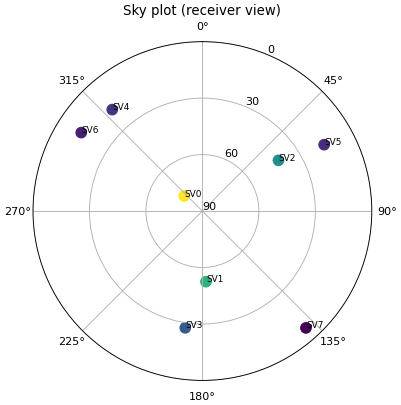

In [2]:
from kalman.apps.gps import GPSModel

# Build a receiver that tracks the 8 highest satellites.
gps = GPSModel("rx", receiver_lat=45.0, receiver_lon=10.0, n_sat=8,
               fs=1.0, pseudorange_uncertainty=1.0)

az, el = gps.azel(0.0)
print(f"{gps.m} satellites, elevations [deg]: {np.round(el, 1)}")

# Simulate 30 minutes of pseudorange measurements at 1 Hz. Relativity is baked in.
chrono.restart()
pseudoranges = gps.simulate(1800.0, seed=0)
chrono.lap("simulated pseudoranges")
print("pseudoranges:", pseudoranges.shape, " mean range ~", round(pseudoranges.mean() / 1e3), "km")

# Sky plot: each point is one satellite, at its azimuth and elevation.
fig = plt.figure(figsize=(5.5, 5.5))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.scatter(np.radians(az), 90 - el, s=90, c=el, cmap="viridis")
for i, (a, e) in enumerate(zip(az, el)):
    ax.annotate(f"SV{i}", (np.radians(a), 90 - e), fontsize=8)
ax.set_rmax(90)
ax.set_rticks([0, 30, 60, 90])
ax.set_yticklabels(["90", "60", "30", "0"])
ax.set_title("Sky plot (receiver view)")
plt.show()


## Step 2 — Compare Results With and Without the Relativistic Correction

Filter the same pseudoranges twice. First, apply the relativistic correction
(`apply_relativistic = True`). Second, remove it (`apply_relativistic = False`).
Start both runs from the same initial guess, about 50 m off.


position RMSE (after convergence):
  GR-corrected :   0.50 m
  uncorrected  :  16.57 m


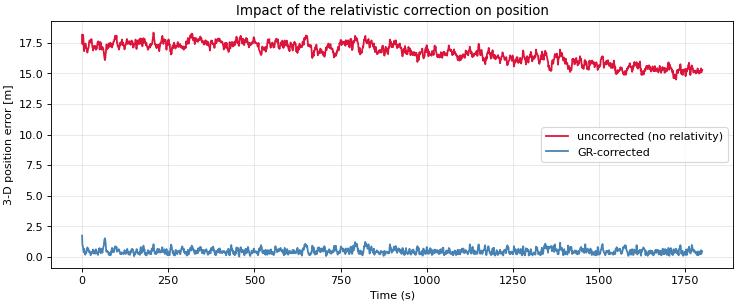

In [3]:
# Start both filters from the same ~50 m offset guess.
guess = np.concatenate([gps.receiver_ecef + [40.0, -30.0, 20.0], [0.0, 0.0]])

gps.apply_relativistic = True
gps.initial_state(guess)
rec_corr = gps.filter(pseudoranges)

gps.apply_relativistic = False
gps.initial_state(guess)
rec_unc = gps.filter(pseudoranges)

t = rec_corr.time
err_corr = gps.position_error(rec_corr)
err_unc = gps.position_error(rec_unc)

# Compare the RMSE after the filter has converged (skip the first 300 s).
rmse_corr = np.sqrt(np.mean(err_corr[300:] ** 2))
rmse_unc = np.sqrt(np.mean(err_unc[300:] ** 2))
print("position RMSE (after convergence):")
print(f"  GR-corrected : {rmse_corr:6.2f} m")
print(f"  uncorrected  : {rmse_unc:6.2f} m")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, err_unc, color="crimson", lw=1.6, label="uncorrected (no relativity)")
ax.plot(t, err_corr, color="steelblue", lw=1.6, label="GR-corrected")
ax.set_xlabel("Time (s)")
ax.set_ylabel("3-D position error [m]")
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("Impact of the relativistic correction on position")
plt.show()


The corrected solution reaches metre-level accuracy. The uncorrected solution keeps a
bias of about 15 m. This bias comes from the per-satellite eccentricity term.

The plot below is the model's signature figure: the East/North/Up error and the
estimated clock, for the uncorrected run.


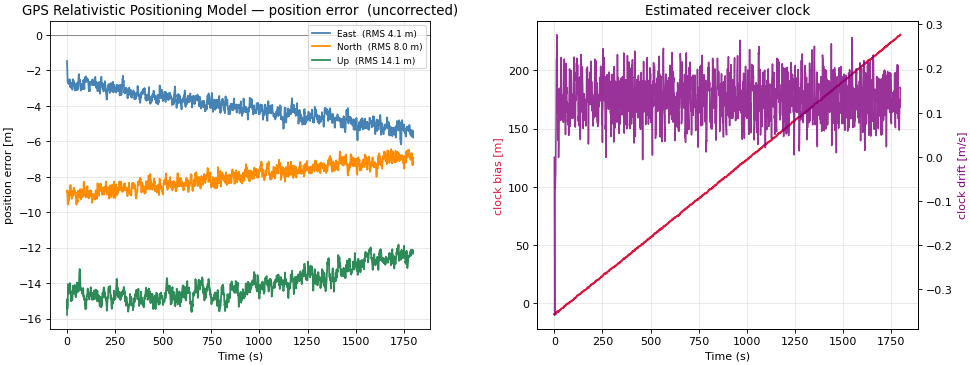

In [4]:
gps.apply_relativistic = False
gps.initial_state(guess)
rec = gps.filter(pseudoranges)
gps.plot(rec, sample=None)
plt.show()


## Step 3 — The Clock Absorbs the 38.6 µs/day Rate

The large secular rate is common to every satellite. The filter cannot separate it
from a receiver clock error. So the filter's clock drift estimate $\dot b$ absorbs
this rate. This is why the filter needs a 4th satellite: to solve for the clock.

The filter measures the relativistic rate directly:
- Without the correction, $\dot b$ converges to about 0.13 m/s. This equals
  38.6 µs/day.
- With the correction, $\dot b$ stays near zero.


expected secular rate : 0.1339 m/s  =  +38.6 us/day  =  11.6 km/day
uncorrected  b_dot    : 0.1562 m/s  =  +45.0 us/day
GR-corrected b_dot    : 0.0223 m/s  =  +6.4 us/day


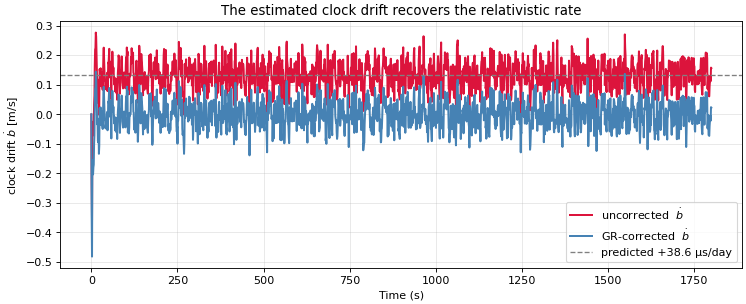

In [5]:
SPEED_OF_LIGHT = 299792458.0

# Expected secular relativistic rate: +38.6 microseconds per day.
secular_rate = SPEED_OF_LIGHT * 38.6e-6 / 86400.0   # m/s

def meters_per_sec_to_us_per_day(v):
    return v / SPEED_OF_LIGHT * 86400.0 * 1e6

b_dot_unc = rec_unc.xk[-1, 4]
b_dot_corr = rec_corr.xk[-1, 4]

print(f"expected secular rate : {secular_rate:.4f} m/s  =  +38.6 us/day  =  {secular_rate * 86.4:.1f} km/day")
print(f"uncorrected  b_dot    : {b_dot_unc:.4f} m/s  =  {meters_per_sec_to_us_per_day(b_dot_unc):+.1f} us/day")
print(f"GR-corrected b_dot    : {b_dot_corr:.4f} m/s  =  {meters_per_sec_to_us_per_day(b_dot_corr):+.1f} us/day")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, rec_unc.xk[:, 4], color="crimson", lw=1.8, label="uncorrected  $\dot b$")
ax.plot(t, rec_corr.xk[:, 4], color="steelblue", lw=1.8, label="GR-corrected  $\dot b$")
ax.axhline(secular_rate, color="gray", ls="--", lw=1.2, label="predicted +38.6 µs/day")
ax.set_xlabel("Time (s)")
ax.set_ylabel("clock drift $\dot b$ [m/s]")
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("The estimated clock drift recovers the relativistic rate")
plt.show()


## Step 4 — The Per-Satellite Eccentricity Correction

The eccentricity term is different for each satellite. So the filter's single clock
state cannot absorb it. This term is what actually biases the position estimate. Its
size depends on each orbit's eccentricity.


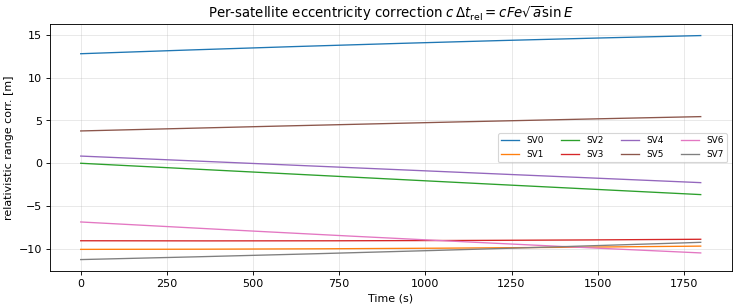

per-satellite correction magnitude: 2.3 - 14.9 m  (differential => ~17 m position bias)


In [6]:
# Per-satellite eccentricity correction: c * delta_t_rel, converted to metres.
ecc_corr = SPEED_OF_LIGHT * gps.constellation.relativistic_seconds(t)   # (N, M) metres

fig, ax = plt.subplots(figsize=(11, 4))
for i in range(gps.m):
    ax.plot(t, ecc_corr[:, i], lw=1.2, label=f"SV{i}")
ax.set_xlabel("Time (s)")
ax.set_ylabel("relativistic range corr. [m]")
ax.legend(fontsize=8, ncol=4)
ax.grid(alpha=0.3)
ax.set_title(r"Per-satellite eccentricity correction $c\,\Delta t_\mathrm{rel}=cFe\sqrt{a}\sin E$")
plt.show()

correction_size = np.abs(ecc_corr).max(axis=0)
print(f"per-satellite correction magnitude: {correction_size.min():.1f} - {correction_size.max():.1f} m  "
      f"(differential => ~{rmse_unc:.0f} m position bias)")


## Step 5 — Satellite Visibility and Real-World Accuracy

So far, the same 8 satellites stayed above the horizon the whole time. In reality,
the satellite constellation moves. Over several hours, satellites rise and set. A
real sky is also partly blocked, for example by buildings, mountains, or trees. Only
satellites above a chosen elevation angle are usable; this angle is called the
*elevation mask*.

`GPSModel(..., elevation_mask=...)` tracks the full 24-satellite constellation. At
each time step, it checks every satellite's elevation. A satellite below the mask is
marked out of sight: its pseudorange becomes `NaN`, and the EKF's masked update skips
it. If fewer than 4 satellites are visible, the filter coasts open-loop on its
dynamics — it cannot compute a position fix.

This example runs for 6 hours, over an obstructed urban sky (a 25° elevation mask).
It shows satellites coming in and out of view, and reads off the precise impact on
the user.


24 satellites tracked;  in view: 2-6 (mean 4.5);  epochs with <4 (no fix): 58  (~29 min of 6 h)


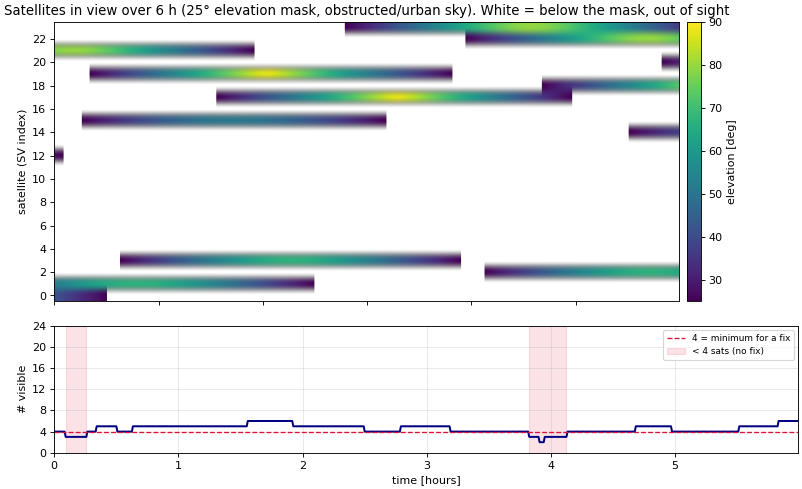

In [7]:
# Track the full constellation through an obstructed urban sky (25 deg elevation mask).
gps2 = GPSModel("rx", receiver_lat=45.0, receiver_lon=10.0, fs=1 / 30.0,
                pseudorange_uncertainty=1.0, elevation_mask=25.0)

DURATION = 6 * 3600.0                              # 6 hours, in seconds
t = np.arange(int(DURATION * gps2.fs)) / gps2.fs
t_hours = t / 3600.0                               # hours, for the x-axis

az, el = gps2.azel_track(t)      # (N, M) azimuth/elevation of every satellite over time
visible = gps2.visible_mask(t)   # (N, M) True where above the mask
n_visible = gps2.n_visible(t)    # (N,) count of visible satellites at each epoch

no_fix_minutes = (n_visible < 4).sum() / gps2.fs / 60
print(f"{gps2.m} satellites tracked;  in view: {n_visible.min()}-{n_visible.max()} "
      f"(mean {n_visible.mean():.1f});  epochs with <4 (no fix): {int((n_visible < 4).sum())}  "
      f"(~{no_fix_minutes:.0f} min of 6 h)")

fig, (a0, a1) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                             gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.12))

elevation_when_visible = np.where(visible, el, np.nan).T
im = a0.imshow(elevation_when_visible, aspect="auto", origin="lower",
               extent=[t_hours[0], t_hours[-1], -0.5, gps2.m - 0.5],
               cmap="viridis", vmin=25, vmax=90)
a0.set_ylabel("satellite (SV index)")
a0.set_yticks(range(0, gps2.m, 2))
a0.set_title("Satellites in view over 6 h (25° elevation mask, obstructed/urban sky). "
             "White = below the mask, out of sight")
fig.colorbar(im, ax=a0, pad=0.01).set_label("elevation [deg]")

a1.plot(t_hours, n_visible, color="navy", lw=1.8)
a1.axhline(4, color="crimson", ls="--", lw=1.2, label="4 = minimum for a fix")
a1.fill_between(t_hours, 0, 1, where=n_visible < 4, transform=a1.get_xaxis_transform(),
                color="crimson", alpha=0.12, step="mid", label="< 4 sats (no fix)")
a1.set_ylabel("# visible")
a1.set_xlabel("time [hours]")
a1.set_ylim(0, gps2.m)
a1.set_yticks(range(0, gps2.m + 1, 4))
a1.legend(fontsize=8, loc="upper right")
a1.grid(alpha=0.3)
plt.show()


### The Cost to the User: Geometry and Ranging Error

The accuracy of a position fix depends on two things: where the visible satellites
are, and how accurate each range measurement is. If the visible satellites are close
together, or if only 4 are visible, the position solution is weak. This effect is
measured by the *dilution of precision* (DOP). To first order, the position error is:

$$\sigma_\text{position} \;\approx\; \text{DOP}\times\sigma_\text{range},$$

so DOP multiplies every ranging error. When satellites set and the geometry weakens,
DOP increases, and so does the position error.

There are two kinds of user to consider:

- A **snapshot (single-epoch) user** computes a fix from one set of measurements at a
  time. This user's error equals $\text{HDOP}\times\sigma$. In open sky this error is
  small, but it can grow to kilometres when the geometry weakens — and if fewer than
  4 satellites are visible, this user has no fix at all.
- A **Kalman filter user** combines measurements over time, using a near-static
  dynamics model. This user keeps metre-level accuracy through periods of weak
  geometry, provided the ranging error itself is small. The relativistic correction
  is what keeps the ranging error small: without it, this user keeps a bias of about
  15–20 m, regardless of geometry.

Both geometry and relativity determine the real-world accuracy of the user.


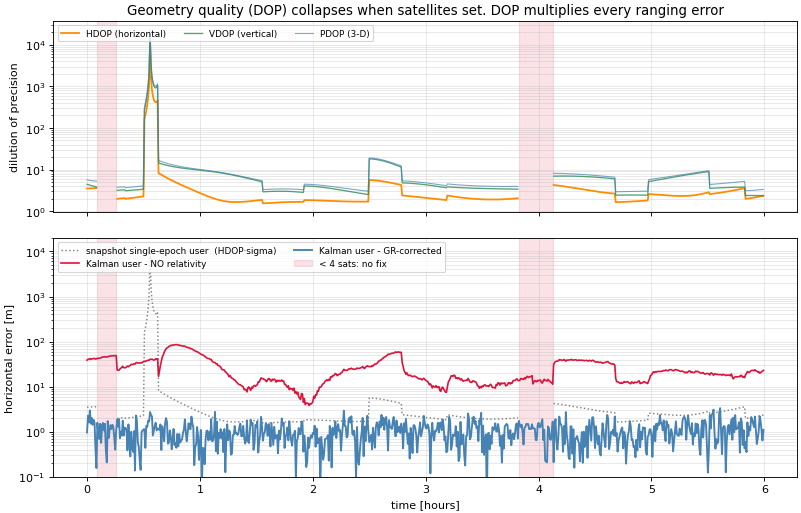

snapshot single-epoch user : median 2.2 m, worst 10619 m
Kalman user, GR-corrected  : median 0.98 m   (rides through the bad geometry)
Kalman user, no relativity : median 19.0 m   (persistent relativistic bias)


In [8]:
D = gps2.dop(t)                                  # geometry quality of the visible satellites
hdop, vdop, pdop = D["hdop"], D["vdop"], D["pdop"]

# Filter the same sky twice: with and without the relativistic correction.
pseudoranges2 = gps2.simulate(DURATION, seed=0)     # out-of-sight satellites come back as NaN
guess = np.concatenate([gps2.receiver_ecef + [40.0, -30.0, 20.0], [0.0, 0.0]])

gps2.apply_relativistic = True
gps2.initial_state(guess)
rec_corr2 = gps2.filter(pseudoranges2)

gps2.apply_relativistic = False
gps2.initial_state(guess)
rec_unc2 = gps2.filter(pseudoranges2)

horiz_err_corr = np.hypot(*gps2.enu_error(rec_corr2)[:, :2].T)   # horizontal error, GR-corrected
horiz_err_unc = np.hypot(*gps2.enu_error(rec_unc2)[:, :2].T)     # horizontal error, no relativity
snapshot_err = hdop * gps2._sigma_rho                            # single-epoch horizontal 1-sigma = HDOP * sigma
outage = n_visible < 4

fig, (b0, b1) = plt.subplots(2, 1, figsize=(12, 7.4), sharex=True,
                             gridspec_kw=dict(height_ratios=[1, 1.25], hspace=0.12))

b0.semilogy(t_hours, hdop, color="darkorange", lw=1.6, label="HDOP (horizontal)")
b0.semilogy(t_hours, vdop, color="seagreen", lw=1.2, alpha=0.8, label="VDOP (vertical)")
b0.semilogy(t_hours, pdop, color="steelblue", lw=1.0, alpha=0.7, label="PDOP (3-D)")
b0.fill_between(t_hours, 0, 1, where=outage, transform=b0.get_xaxis_transform(),
                color="crimson", alpha=0.12, step="mid")
b0.set_ylabel("dilution of precision")
b0.grid(alpha=0.3, which="both")
b0.legend(fontsize=8, ncol=3, loc="upper left")
b0.set_title("Geometry quality (DOP) collapses when satellites set. DOP multiplies every ranging error")

b1.semilogy(t_hours, np.clip(snapshot_err, 1e-2, None), color="0.5", lw=1.3, ls=":",
            label="snapshot single-epoch user  (HDOP·sigma)")
b1.semilogy(t_hours, np.clip(horiz_err_unc, 1e-2, None), color="crimson", lw=1.5,
            label="Kalman user - NO relativity")
b1.semilogy(t_hours, np.clip(horiz_err_corr, 1e-2, None), color="steelblue", lw=1.7,
            label="Kalman user - GR-corrected")
b1.fill_between(t_hours, 0, 1, where=outage, transform=b1.get_xaxis_transform(),
                color="crimson", alpha=0.12, step="mid", label="< 4 sats: no fix")
b1.set_ylabel("horizontal error [m]")
b1.set_xlabel("time [hours]")
b1.set_ylim(0.1, 2e4)
b1.grid(alpha=0.3, which="both")
b1.legend(fontsize=8, ncol=2, loc="upper left")
plt.show()

print(f"snapshot single-epoch user : median {np.nanmedian(snapshot_err):.1f} m, worst {np.nanmax(snapshot_err):.0f} m")
print(f"Kalman user, GR-corrected  : median {np.median(horiz_err_corr[20:]):.2f} m   (rides through the bad geometry)")
print(f"Kalman user, no relativity : median {np.median(horiz_err_unc[20:]):.1f} m   (persistent relativistic bias)")


## Takeaways

- GPS positioning is an EKF over the state $[x,y,z,b,\dot b]$. The pseudorange
  measurement is nonlinear. The framework computes it with an analytic
  line-of-sight Jacobian.
- The net relativistic rate is +38.6 µs/day (SR: −7.2 µs/day, GR: +45.9 µs/day).
  This rate is common to every satellite. The filter's clock drift estimate
  absorbs it, to within about 1 µs/day.
- The per-satellite eccentricity correction ($cFe\sqrt{a}\sin E$) is what biases
  the position. Removing this term takes the solution from about 15 m to
  metre-level accuracy.
- Every real GPS receiver applies this relativistic correction. Without it, GPS
  positions would be wrong by tens of metres, and the clock error would grow by
  kilometres per day.
- Satellites rise and set. Over several hours, the set of visible satellites
  changes. In an obstructed sky, some satellites drop out of view. If fewer than
  4 remain, there is no position fix. The `elevation_mask` setting makes the EKF
  skip out-of-sight satellites, using a NaN-masked update.
- DOP approximately multiplies the ranging error:
  $\sigma_\text{position}\approx\mathrm{DOP}\times\sigma_\text{range}$, to first
  order. A single-epoch user in poor geometry can be off by kilometres. The
  Kalman filter user keeps metre-level accuracy through the same conditions,
  because the relativistic correction keeps the ranging error small. Real-world
  accuracy depends on both geometry and relativity.
